# Regresión Lineal con Python

**Fuente:** [aprendemachinelearning.com](https://www.aprendemachinelearning.com/regresion-lineal-en-espanol-con-python/)  
**Autor:** Na8 (Juan Ignacio Bagnato)

**Ejecución y transcripcion a Colab:** Carlos Francisco Montoya Urzua

---



## ¿Qué es la regresión lineal?

La **regresión lineal** es un algoritmo de **aprendizaje supervisado** que se utiliza en Machine Learning y en estadística. En su versión más sencilla, lo que haremos es "dibujar una recta" que *nos indicará la tendencia* de un conjunto de datos continuos (si fueran discretos, utilizaríamos Regresión Logística).

En estadísticas, *regresión lineal es una aproximación para modelar la relación entre una variable escalar dependiente "y" y una o más variables explicativas nombradas con "X"*.

Recordemos rápidamente la fórmula de la recta:

> **Y = mX + b**

Donde **Y** es el resultado, **X** es la variable, **m** la pendiente (o coeficiente) de la recta y **b** la constante o también conocida como el "punto de corte con el eje Y" en la gráfica (cuando X=0).

Aquí vemos un ejemplo donde vemos datos recabados sobre los precios de las pizzas en Dinamarca (los puntos en rojo) y la línea negra es la tendencia. Esa es la línea de regresión que buscamos que el algoritmo aprenda y calcule sólo.

## ¿Cómo funciona el algoritmo de regresión lineal en Machine Learning?

Recordemos que los **algoritmos de Machine Learning Supervisados** aprenden por sí mismos y —en este caso— a obtener automáticamente esa "recta" que buscamos con la tendencia de predicción. Para hacerlo se mide el error con respecto a los puntos de entrada y el valor "Y" de salida real. El algoritmo deberá minimizar el coste de una función de **error cuadrático** y esos coeficientes corresponderán con la recta óptima. Hay diversos métodos para conseguir minimizar el coste. Lo más común es utilizar una versión vectorial y la llamada **Ecuación Normal** que nos dará un resultado directo.

> **NOTA:** cuando hablo de "recta" es en el caso particular de regresión lineal simple. Si hubiera más variables, hay que generalizar el término.

## Hagamos un Ejercicio Práctico

En este ejemplo cargaremos un **archivo .csv de entrada** que contiene diversas URLs a artículos sobre Machine Learning de algunos sitios muy importantes como Techcrunch o KDnuggets. Las columnas (características de entrada) son:

- **Title**: Título del Artículo
- **url**: ruta al artículo
- **Word count**: la cantidad de palabras del artículo
- **# of Links**: los enlaces externos que contiene
- **# of comments**: cantidad de comentarios
- **# Images video**: suma de imágenes (o videos)
- **Elapsed days**: la cantidad de días transcurridos (al momento de crear el archivo)
- **# Shares**: nuestra columna de **salida** que será la "cantidad de veces que se compartió el artículo"

*A partir de las características de un artículo de machine learning intentaremos predecir cuántas veces será compartido en Redes Sociales.*

Haremos una primera predicción de **regresión lineal simple** —con una sola variable predictora— para poder graficar en 2 dimensiones (ejes X e Y) y luego un ejemplo de **regresión Lineal Múltiple**, en la que utilizaremos 3 dimensiones (X, Y, Z) y predicciones.

> **NOTA:** el archivo .csv contiene mitad de datos reales, y otra mitad generados de manera aleatoria, por lo que las predicciones que obtendremos no serán completamente reales.

# Predecir cuántas veces será compartido un artículo de Machine Learning

## Regresión Lineal Simple en Python (con 1 variable)

¡Aquí vamos con nuestra notebook!

Comencemos por importar las librerías que utilizaremos:

In [1]:
# Imports necesarios
import numpy as np
import pandas as pd
import seaborn as sb
import matplotlib.pyplot as plt
%matplotlib inline
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm
plt.rcParams['figure.figsize'] = (16, 9)
plt.style.use('ggplot')
from sklearn import linear_model
from sklearn.metrics import mean_squared_error, r2_score

Leemos el archivo csv y lo cargamos como un dataset de Pandas. Y vemos su tamaño:

In [2]:
# Cargamos los datos de entrada
data = pd.read_csv("./articulos_ml.csv")
# Veamos cuántas dimensiones y registros contiene
data.shape

(161, 8)

In [3]:
#SOLO PARA PROBAR EL CONTENIDO
data

,Title,url,Word count,# of Links,# of comments,# Images video,Elapsed days,# Shares
0,What is Machine Learning and how do we use it ...,https://blog.signals.network/what-is-machine-l...,1888,1,2.0,2,34,200000
1,10 Companies Using Machine Learning in Cool Ways,NaN,1742,9,NaN,9,5,25000
2,How Artificial Intelligence Is Revolutionizing...,NaN,962,6,0.0,1,10,42000
3,Dbrain and the Blockchain of Artificial Intell...,NaN,1221,3,NaN,2,68,200000
4,Nasa finds entire solar system filled with eig...,NaN,2039,1,104.0,4,131,200000
...,...,...,...,...,...,...,...,...
156,[Log] 83: How Google Uses Machine Learning And...,[Log] 83: http://feedproxy.google.com/~r/Techc...,3239,3,11.0,1,84,3239
157,[Log] 84: Zuck Knows If You've Been Bad Or Goo...,[Log] 84: http://feedproxy.google.com/~r/Techc...,2566,3,8.0,4,85,25019
158,[Log] 85: Microsoft Improves Windows Phone Voi...,[Log] 85: http://feedproxy.google.com/~r/Techc...,2089,4,4.0,1,86,49614
159,[Log] 86: How Google's Acquisition Of DNNresea...,[Log] 86: http://feedproxy.google.com/~r/Techc...,1530,4,12.0,3,87,33660


Nos devuelve **(161, 8)**

Veamos esas primeras filas:

In [4]:
# Son 161 registros con 8 columnas. Veamos los primeros registros
data.head()

,Title,url,Word count,# of Links,# of comments,# Images video,Elapsed days,# Shares
0,What is Machine Learning and how do we use it ...,https://blog.signals.network/what-is-machine-l...,1888,1,2.0,2,34,200000
1,10 Companies Using Machine Learning in Cool Ways,NaN,1742,9,NaN,9,5,25000
2,How Artificial Intelligence Is Revolutionizing...,NaN,962,6,0.0,1,10,42000
3,Dbrain and the Blockchain of Artificial Intell...,NaN,1221,3,NaN,2,68,200000
4,Nasa finds entire solar system filled with eig...,NaN,2039,1,104.0,4,131,200000


Se ven algunos campos con valores NaN (nulos) por ejemplo algunas urls o en comentarios.

Veamos algunas estadísticas básicas de nuestros datos de entrada:

In [5]:
# Ahora veamos algunas estadísticas de nuestros datos
data.describe()

,Word count,# of Links,# of comments,# Images video,Elapsed days,# Shares
count,161.000000,161.000000,129.000000,161.000000,161.000000,161.000000
mean,1808.260870,9.739130,8.782946,3.670807,98.124224,27948.347826
std,1141.919385,47.271625,13.142822,3.418290,114.337535,43408.006839
min,250.000000,0.000000,0.000000,1.000000,1.000000,0.000000
25%,990.000000,3.000000,2.000000,1.000000,31.000000,2800.000000
50%,1674.000000,5.000000,6.000000,3.000000,62.000000,16458.000000
75%,2369.000000,7.000000,12.000000,5.000000,124.000000,35691.000000
max,8401.000000,600.000000,104.000000,22.000000,1002.000000,350000.000000


Aquí vemos que la media de palabras en los artículos es de **1808**. El artículo más corto tiene 250 palabras y el más extenso 8401. Intentaremos ver con nuestra relación lineal, si hay una correlación entre la cantidad de palabras del texto y la cantidad de Shares obtenidos.

Hacemos una visualización en general de los datos de entrada:

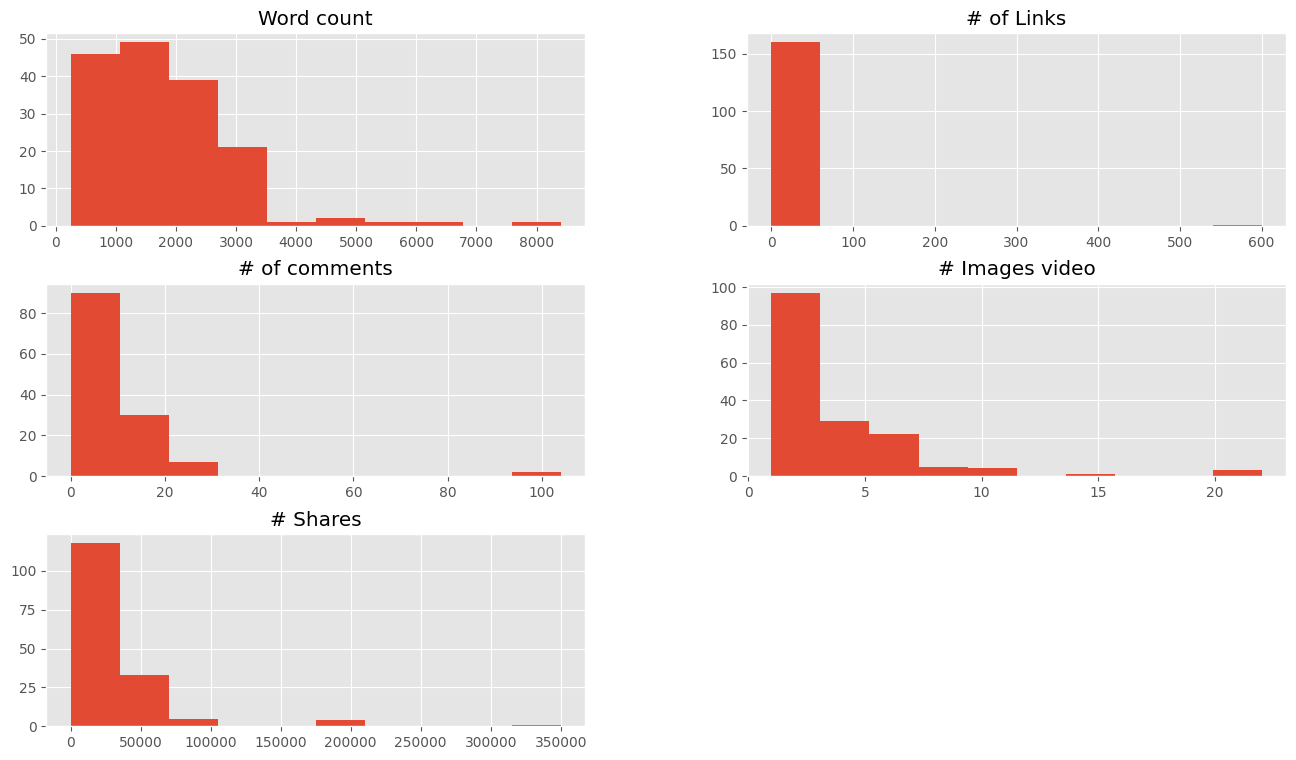

In [7]:
# Visualizamos rápidamente las características de entrada
#data.drop(['Title','url', 'Elapsed days'],1).hist()
data.drop(['Title','url', 'Elapsed days'], axis=1).hist()
plt.show()

En estas gráficas vemos entre qué valores se concentran la mayoría de registros.

Vamos a filtrar los datos de cantidad de palabras para quedarnos con los registros con menos de 3500 palabras y también con los que tengan cantidad de compartidos menor a 80.000. Lo graficaremos pintando en **azul** los puntos con menos de 1808 palabras (la media) y en **naranja** los que tengan más.

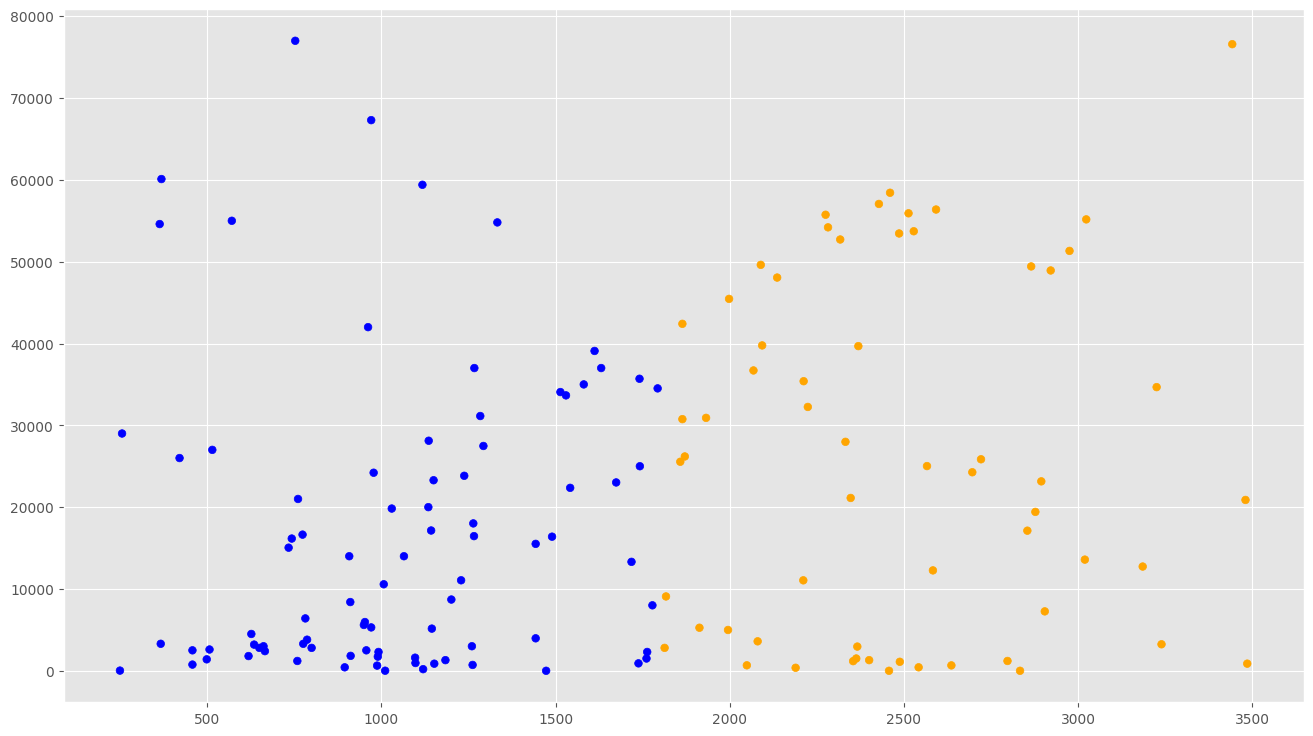

In [8]:
# Vamos a RECORTAR los datos en la zona donde se concentran más los puntos
# esto es en el eje X: entre 0 y 3.500
# y en el eje Y: entre 0 y 80.000
filtered_data = data[(data['Word count'] <= 3500) & (data['# Shares'] <= 80000)]

colores=['orange','blue']
tamanios=[30,60]

f1 = filtered_data['Word count'].values
f2 = filtered_data['# Shares'].values

# Vamos a pintar en colores los puntos por debajo y por encima de la media de Cantidad de Palabras
asignar=[]
for index, row in filtered_data.iterrows():
    if(row['Word count']>1808):
        asignar.append(colores[0])
    else:
        asignar.append(colores[1])

plt.scatter(f1, f2, c=asignar, s=tamanios[0])
plt.show()

## Regresión Lineal con Python y SKLearn

Vamos a crear nuestros datos de entrada —por el momento sólo **Word Count**— y como etiquetas los **# Shares**. Creamos el objeto `LinearRegression` y lo hacemos "encajar" (entrenar) con el método `fit()`. Finalmente imprimimos los coeficientes y puntajes obtenidos.

In [9]:
# Asignamos nuestra variable de entrada X para entrenamiento y las etiquetas Y.
dataX = filtered_data[["Word count"]]
X_train = np.array(dataX)
y_train = filtered_data['# Shares'].values

# Creamos el objeto de Regresión Linear
regr = linear_model.LinearRegression()

# Entrenamos nuestro modelo
regr.fit(X_train, y_train)

# Hacemos las predicciones que en definitiva una línea (en este caso, al ser 2D)
y_pred = regr.predict(X_train)

# Veamos los coeficientes obtenidos, En nuestro caso, serán la Tangente
print('Coefficients: \n', regr.coef_)
# Este es el valor donde corta el eje Y (en X=0)
print('Independent term: \n', regr.intercept_)
# Error Cuadrado Medio
print("Mean squared error: %.2f" % mean_squared_error(y_train, y_pred))
# Puntaje de Varianza. El mejor puntaje es un 1.0
print('Variance score: %.2f' % r2_score(y_train, y_pred))

Coefficients: 
 [5.69765366]
Independent term: 
 11200.30322307416
Mean squared error: 372888728.34
Variance score: 0.06


De la ecuación de la recta **y = mX + b**, nuestra pendiente "m" es el coeficiente **5,69** y el término independiente "b" es **11200**. Tenemos un Error Cuadrático medio enorme… por lo que en realidad este modelo no será muy bueno 😉 Pero estamos aprendiendo a usarlo, que es lo que nos importa ahora 🙂 Esto también se ve reflejado en el puntaje de Varianza que debería ser cercano a 1.0.

## Visualicemos la Recta

Veamos la recta que obtuvimos:

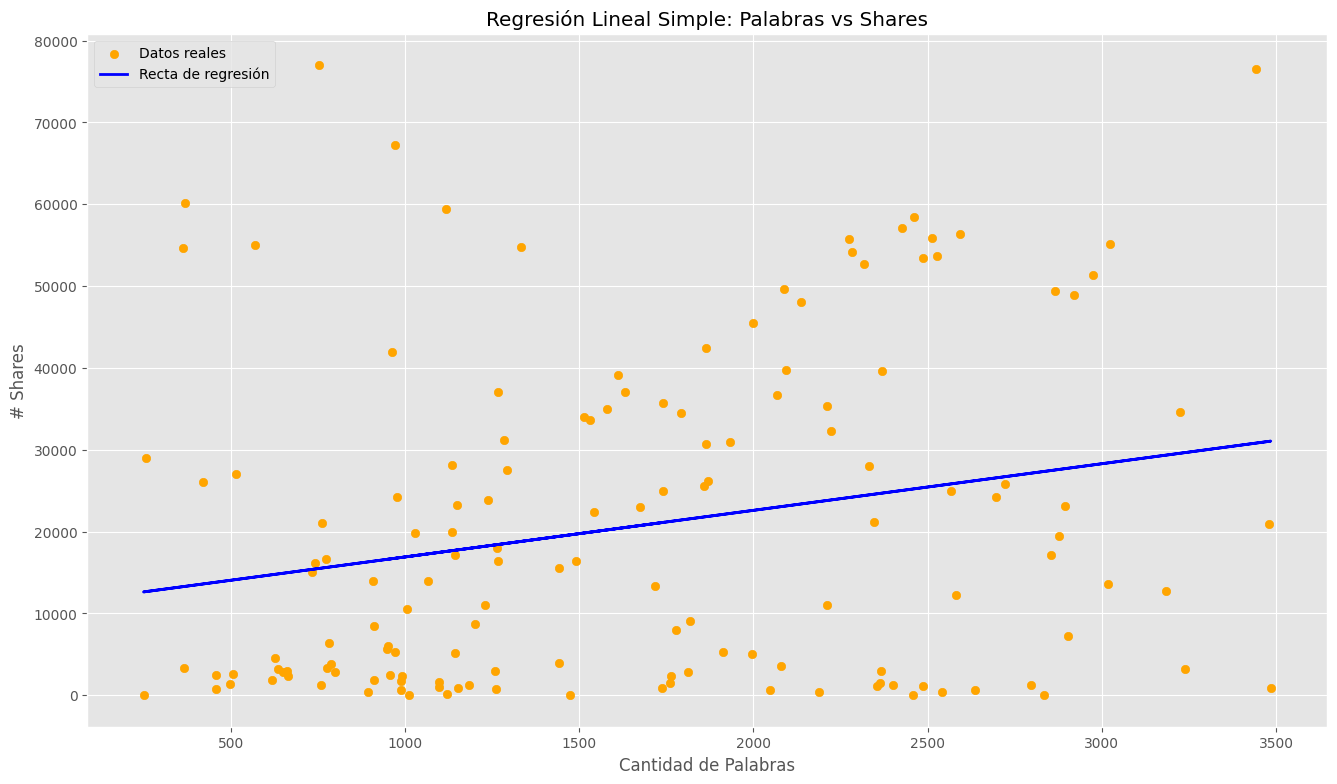

In [10]:
# Graficamos los puntos de entrenamiento y la recta de regresión obtenida
plt.scatter(X_train, y_train, color='orange', label='Datos reales')
plt.plot(X_train, y_pred, color='blue', linewidth=2, label='Recta de regresión')
plt.xlabel('Cantidad de Palabras')
plt.ylabel('# Shares')
plt.title('Regresión Lineal Simple: Palabras vs Shares')
plt.legend()
plt.show()

## Predicción en Regresión Lineal Simple

Vamos a intentar probar nuestro algoritmo, suponiendo que quisiéramos predecir cuántos "compartir" obtendrá un artículo sobre ML de **2000 palabras**:

In [11]:
# Vamos a comprobar:
# Quiero predecir cuántos "Shares" voy a obtener por un artículo con 2.000 palabras,
# según nuestro modelo, hacemos:
y_Dosmil = regr.predict([[2000]])
print(int(y_Dosmil))

22595


/tmp/ipykernel_1535/2202011489.py:5: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  print(int(y_Dosmil))


Nos devuelve una predicción de **22595** "Shares" para un artículo de 2000 palabras (¡ya quisiera yo!).

---

# Regresión Lineal Múltiple en Python
## (o "Regresión con Múltiples Variables")

Vamos a extender el ejercicio utilizando más de una variable de entrada para el modelo. Esto le da **mayor poder** al algoritmo de Machine Learning, pues de esta manera podremos obtener predicciones más complejas.

Nuestra "ecuación de la Recta", ahora pasa a ser:

> **Y = b + m1·X1 + m2·X2 + … + m(n)·X(n)**

y deja de ser una recta.

**En nuestro caso, utilizaremos 2 "variables predictivas" para poder graficar en 3D**, pero recordar que *para mejores predicciones podemos utilizar más de 2 entradas* y prescindir del gráfico.

Nuestra primera variable seguirá siendo la **cantidad de palabras** y la segunda variable será **la suma de 3 columnas de entrada**: la cantidad de enlaces, comentarios y cantidad de imágenes. ¡Vamos a programar!

In [12]:
# Vamos a intentar mejorar el Modelo, con una dimensión más:
# Para poder graficar en 3D, haremos una variable nueva que será la suma de los enlaces, comentarios e imágenes
suma = (filtered_data["# of Links"] + filtered_data['# of comments'].fillna(0) + filtered_data['# Images video'])

dataX2 = pd.DataFrame()
dataX2["Word count"] = filtered_data["Word count"]
dataX2["suma"] = suma

XY_train = np.array(dataX2)
z_train = filtered_data['# Shares'].values

In [13]:
dataX2

,Word count,suma
1,1742,18.0
2,962,7.0
5,761,1.0
7,753,4.0
8,1118,3.0
...,...,...
156,3239,15.0
157,2566,15.0
158,2089,9.0
159,1530,19.0


In [14]:
XY_train

array([[1.742e+03, 1.800e+01],
       [9.620e+02, 7.000e+00],
       [7.610e+02, 1.000e+00],
       [7.530e+02, 4.000e+00],
       [1.118e+03, 3.000e+00],
       [1.581e+03, 6.000e+00],
       [2.560e+02, 2.800e+01],
       [1.267e+03, 6.000e+00],
       [9.710e+02, 1.100e+01],
       [3.690e+02, 7.000e+00],
       [6.350e+02, 6.000e+00],
       [1.631e+03, 2.100e+01],
       [5.710e+02, 5.000e+00],
       [1.333e+03, 1.200e+01],
       [3.640e+02, 7.000e+00],
       [5.150e+02, 7.000e+00],
       [1.135e+03, 9.000e+00],
       [6.660e+02, 7.000e+00],
       [7.870e+02, 5.000e+00],
       [4.210e+02, 3.000e+00],
       [1.065e+03, 2.100e+01],
       [9.080e+02, 3.000e+00],
       [1.260e+03, 1.100e+01],
       [9.500e+02, 7.000e+00],
       [1.761e+03, 6.300e+01],
       [9.110e+02, 3.400e+01],
       [9.710e+02, 7.000e+00],
       [4.580e+02, 3.000e+00],
       [4.580e+02, 6.000e+00],
       [7.820e+02, 1.400e+01],
       [2.080e+03, 8.000e+00],
       [2.500e+02, 7.000e+00],
       [

In [15]:
z_train

array([25000, 42000, 21000, 77000, 59400, 35000, 29000, 37000, 67300,
       60100,  3200, 37000, 55000, 54800, 54600, 27000, 20000,  2400,
        3800, 26000, 14000, 14000,  3000,  5600,  1500,  8400,  5300,
        2500,   757,  6400,  3600,    22,  2300,  2800,  1300,  2500,
        4500,   422,  1600,   715,   907,  2800,  1300,  3000,  2800,
        3300,  2600,  2300,  1400,  1800,   867,  1500,   631,  1200,
         950,  1200,   196,  1100,   668,   424,     8,   367, 42406,
        1733, 35691, 11061, 51319, 30756, 58425, 48060,     0,  4988,
       27984, 45455, 76585, 24264,  5261, 25548,     0, 56376, 13315,
       27476, 55170,   871, 39767, 16390, 23832, 12269, 10574, 24206,
       13586, 21123, 32248,  8001, 23288, 53720, 53449, 52712, 39681,
       39091, 28116, 25850, 20880, 17145, 57058, 19420,  3298, 31137,
        5153, 34515,  7260,     0, 23152, 30912, 34669, 12740, 36707,
        1177, 48927, 11055, 49421, 23018, 54198,   659, 16641, 19828,
       15047, 16160,

> **Nota:** hubiera sido mejor aplicar PCA para reducción de dimensiones, manteniendo la información más importante de todas.

Ya tenemos nuestras 2 variables de entrada en `XY_train` y **nuestra variable de salida pasa de ser "Y" a ser el eje "Z"**.

Creamos un nuevo objeto de Regresión lineal con SKLearn pero esta vez tendrá las dos dimensiones que entrenar: las que contiene `XY_train`. Al igual que antes, imprimimos los coeficientes y puntajes obtenidos:

In [16]:
# Creamos un nuevo objeto de Regresión Lineal
regr2 = linear_model.LinearRegression()

# Entrenamos el modelo, esta vez, con 2 dimensiones
# obtendremos 2 coeficientes, para graficar un plano
regr2.fit(XY_train, z_train)

# Hacemos la predicción con la que tendremos puntos sobre el plano hallado
z_pred = regr2.predict(XY_train)

# Los coeficientes
print('Coefficients: \n', regr2.coef_)
# Error cuadrático medio
print("Mean squared error: %.2f" % mean_squared_error(z_train, z_pred))
# Evaluamos el puntaje de varianza (siendo 1.0 el mejor posible)
print('Variance score: %.2f' % r2_score(z_train, z_pred))

Coefficients: 
 [   6.63216324 -483.40753769]
Mean squared error: 352122816.48
Variance score: 0.11


Como vemos, obtenemos **2 coeficientes** (cada uno correspondiente a nuestras 2 variables predictivas), pues ahora lo que graficamos no será una línea sino **un plano en 3 Dimensiones**.

El error obtenido sigue siendo grande, aunque algo mejor que el anterior y el puntaje de Varianza mejora casi el doble del anterior (aunque sigue siendo muy malo, muy lejos del 1).

## Visualizar un Plano en 3 Dimensiones en Python

Graficaremos nuestros puntos de las características de entrada en color **azul** y los puntos proyectados en el plano en **rojo**. Recordemos que en esta gráfica, el eje Z corresponde a la "altura" y representa la cantidad de Shares que obtendremos.

Text(0.5, 0.92, 'Regresión Lineal con Múltiples Variables')

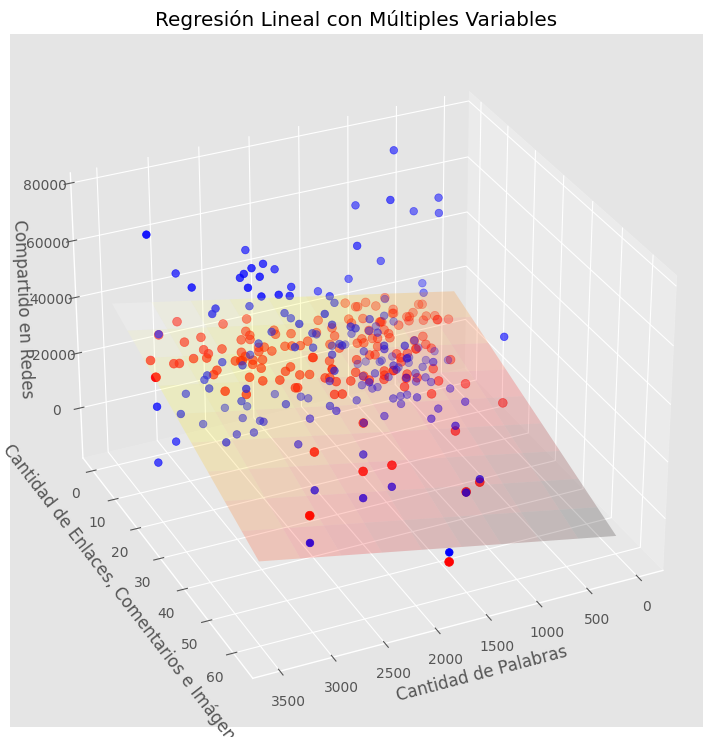

In [23]:
fig = plt.figure()
#ax = Axes3D(fig)
ax = fig.add_subplot(111, projection='3d')

# Creamos una malla, sobre la cual graficaremos el plano
xx, yy = np.meshgrid(np.linspace(0, 3500, num=10), np.linspace(0, 60, num=10))

# Calculamos los valores del plano para los puntos x e y
nuevoX = (regr2.coef_[0] * xx)
nuevoY = (regr2.coef_[1] * yy)

# Calculamos los correspondientes valores para z. Debemos sumar el punto de intercepción
z = (nuevoX + nuevoY + regr2.intercept_)

# Graficamos el plano
ax.plot_surface(xx, yy, z, alpha=0.2, cmap='hot')

# Graficamos en azul los puntos en 3D
ax.scatter(XY_train[:, 0], XY_train[:, 1], z_train, c='blue', s=30)

# Graficamos en rojo, los puntos predichos
ax.scatter(XY_train[:, 0], XY_train[:, 1], z_pred, c='red', s=40)

# Con esto situamos la "cámara" con la que visualizamos
ax.view_init(elev=30., azim=65)

ax.set_xlabel('Cantidad de Palabras')
ax.set_ylabel('Cantidad de Enlaces, Comentarios e Imágenes')
ax.set_zlabel('Compartido en Redes')
ax.set_title('Regresión Lineal con Múltiples Variables')

Podemos rotar el gráfico para apreciar el plano desde diversos ángulos modificando el valor del parámetro **azim** en `view_init` con números de 0 a 360.

## Predicción con el Modelo de Múltiples Variables

Veamos ahora qué predicción tendremos para un artículo de **2000 palabras**, con **10 enlaces**, **4 comentarios** y **6 imágenes**.

In [24]:
# Si quiero predecir cuántos "Shares" voy a obtener por un artículo con:
# 2000 palabras y con enlaces: 10, comentarios: 4, imágenes: 6
# según nuestro modelo, hacemos:
z_Dosmil = regr2.predict([[2000, 10+4+6]])
print(int(z_Dosmil))

20518


/tmp/ipykernel_1535/2132555510.py:5: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  print(int(z_Dosmil))


Esta predicción nos da **20518** y probablemente sea un poco mejor que nuestra predicción anterior con 1 variable.

---

## Conclusión y Mejora de nuestro modelo

Hemos visto cómo utilizar SKLearn en Python para crear modelos de Regresión Lineal con 1 o múltiples variables. En nuestro ejercicio no tuvimos una gran confianza en las predicciones. Por ejemplo en nuestro primer modelo, con 2000 palabras nos predice que podemos tener 22595 pero el margen de error haciendo raíz del error cuadrático medio es más menos 19310. Es decir que escribiendo un artículo de 2000 palabras lo mismo tenemos 3285 Shares que 41905.

En este caso usamos este modelo para **aprender a usarlo** y habrá que ver en otros casos en los que sí nos brinde predicciones acertadas.

Para mejorar nuestro modelo, deberíamos utilizar más dimensiones y encontrar datos de entrada mejores.

> **Atención:** también es posible que no exista ninguna relación nunca entre nuestras variables de entrada y el éxito en Shares del artículo… con lo cual… nunca podremos predecir con certeza esta salida. ¡Esto fue un experimento!

#ESTUVE TRANSCRIBIENDO TODO PARA AL FINAL DARME CUENTA QUE SE PODIA DESCARGAR EL ARCHIVO ORIGINAL

https://github.com/jbagnato/machine-learning/blob/master/Ejercicio_Regresion_Lineal.ipynb